In [1]:
%pip install qiskit==2.1.2 qiskit-optimization==0.7.0 networkx matplotlib numpy --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import random
import math
from qiskit_optimization import QuadraticProgram
from qiskit.primitives import StatevectorSampler
from qiskit_optimization.algorithms import GroverOptimizer
from qiskit_optimization.converters import QuadraticProgramToQubo
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import DiagonalGate

## **<u>GROVER ADAPTIVE SEARCH FOR QUBO</u>** 

In [3]:
class GroverAdaptiveSearch:
    '''Uses Grover search repeatedly to find the minima of a QUBO'''

    def __init__(self, Q, lam=1.2, seed=42, constant=0):

        self.Q = np.asarray(Q, dtype=float)

        self.n = self.Q.shape[0]
        self.N = 2 ** self.n

        self.lam = lam
        self.constant = constant
        self.rng = random.Random(seed)

        # Initial random solution
        self.best_index = self.rng.randrange(self.N)
        self.best_solution = self.decode(self.best_index)
        self.best_value = self.qubo(self.best_solution)

        self.history = []

    def decode(self, index):
        return np.array([
            (index >> i) & 1
            for i in range(self.n)
        ])

    def qubo(self, x):
        # Include the constant term
        return float(x @ self.Q @ x + self.constant)

    def oracle(self, threshold):

        phases = []

        for i in range(self.N):

            x = self.decode(i)
            cost = self.qubo(x)

            if cost < threshold:
                phases.append(-1)
            else:
                phases.append(1)

        return DiagonalGate(phases)

    def diffuser(self):

        qc = QuantumCircuit(self.n)

        qc.h(range(self.n))
        qc.x(range(self.n))

        qc.h(self.n - 1)
        qc.mcx(list(range(self.n - 1)), self.n - 1)
        qc.h(self.n - 1)

        qc.x(range(self.n))
        qc.h(range(self.n))

        return qc

    def grover_circuit(self, threshold, iterations):

        qc = QuantumCircuit(self.n)

        qc.h(range(self.n))

        oracle = self.oracle(threshold)
        diffuser = self.diffuser()

        for _ in range(iterations):

            qc.append(oracle, range(self.n))
            qc.compose(diffuser, inplace=True)

        return qc

    def measure(self, threshold, iterations):

        qc = self.grover_circuit(threshold, iterations)

        state = Statevector.from_instruction(qc)
        probabilities = state.probabilities()

        result = self.rng.choices(
            range(self.N),
            weights=probabilities,
            k=1
        )[0]

        return result

    def run(self, max_rounds=100):

        m = 1.0
        max_m = math.sqrt(self.N)

        print("Initial solution:", self.best_solution)
        print("Initial cost:", self.best_value)

        print("\n> Starting Grover Adaptive Search\n")

        for iteration in range(max_rounds):

            # Randomly select Grover iterations, including zero
            j = self.rng.randrange(max(1, math.ceil(m)))

            candidate_index = self.measure(self.best_value, j)

            candidate = self.decode(candidate_index)
            candidate_cost = self.qubo(candidate)

            improved = False

            if candidate_cost < self.best_value:

                self.best_index = candidate_index
                self.best_solution = candidate
                self.best_value = candidate_cost

                m = 1.0
                improved = True

            else:
                m = min(self.lam * m, max_m)

            current_info = {
                "Round": iteration + 1,
                "Grover_iterations": j,
                "Candidate": candidate.tolist(),
                "Candidate_cost": candidate_cost,
                "Best_solution": self.best_solution.tolist(),
                "Best_cost": self.best_value,
                "Improved": improved,
                "m": m
            }

            self.history.append(current_info)
            print(current_info)

        return self.best_solution, self.best_value

### **<u>Define network graph</u>** 

In [4]:
random.seed(42)
np.random.seed(42)

V = 6   # number of nodes

In [5]:
def draw_network_graph(R, title):
    plt.figure(figsize=(10, 7))
    pos = nx.spring_layout(R, seed=42, k=8, iterations=100)
    edge_labels = nx.get_edge_attributes(R, "weight")
    nx.draw_networkx_nodes(R, pos, node_size=1800, node_color="skyblue")
    nx.draw_networkx_edges(R, pos, arrows=True, min_target_margin=20)
    nx.draw_networkx_labels(R, pos, font_weight="bold")
    nx.draw_networkx_edge_labels(R, pos, edge_labels=edge_labels, font_size=10, font_weight="bold", font_color="darkred")
    plt.title(title)
    plt.show()

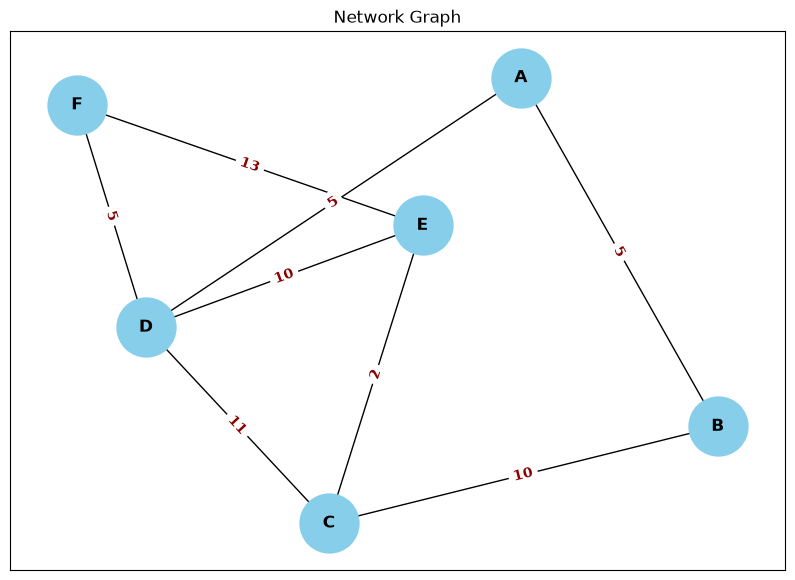

In [6]:
G = nx.Graph()
G.add_nodes_from(chr(65+i) for i in range(V))

for i in range(V - 1):
    G.add_edge(chr(65+i), chr(65+i + 1))    # create a path from node 0 to node 5

for i in range(V):
    for j in range(i + 2, V):
        if random.random() < 0.2:
            G.add_edge(chr(65+i), chr(65+j))    # random edges

for u, v in G.edges():
    G[u][v]["weight"] = random.randint(2, 15)   # random cost

SOURCE = chr(65)  # 'A'
DESTINATION = chr(65 + V - 1)  

draw_network_graph(G, "Network Graph")

In [7]:
edges = list(G.edges())
vertices = list(G.nodes())

V = len(vertices)
E = len(edges)

degree = {v: 0 for v in vertices}

for u, v in edges:
    degree[u] += 1
    degree[v] += 1

degree

{'A': 2, 'B': 2, 'C': 3, 'D': 4, 'E': 3, 'F': 2}

In [8]:
vertices_without_source_destination = list(filter(lambda item: item not in [SOURCE, DESTINATION], vertices))
vertices_without_source_destination

['B', 'C', 'D', 'E']

### **<u>Define QUBO problem</u>** 

In [9]:
qp = QuadraticProgram("Shortest_Path_QUBO")

x = {} # binary variable for each edge

for i, (u, v) in enumerate(edges):
    x[(u, v)] = f"({u},{v})"
    qp.binary_var(name=x[(u, v)])

y = {} # auxiliary variables
for vertex in vertices_without_source_destination:
    y[vertex] = f"include_{vertex}"
    qp.binary_var(name=y[vertex])

In [10]:
total_edge_cost = {       # minimize total edge cost
    x[(u, v)]: G[u][v]["weight"]
    for u, v in edges
}

total_edge_cost

{'(A,B)': 5,
 '(A,D)': 5,
 '(B,C)': 10,
 '(C,D)': 11,
 '(C,E)': 2,
 '(D,E)': 10,
 '(D,F)': 5,
 '(E,F)': 13}

In [11]:
qp.minimize(linear=total_edge_cost)

# source degree = 1
qp.linear_constraint(
    linear={
        x[(u, v)]: 1
        for u, v in edges
        if u == SOURCE or v == SOURCE
    },
    sense="==",
    rhs=1,
    name="must_start_from_source"
)

# destination degree = 1
qp.linear_constraint(
    linear={
        x[(u, v)]: 1
        for u, v in edges
        if u == DESTINATION or v == DESTINATION
    },
    sense="==",
    rhs=1,
    name="must_end_at_destination"
)

# intermediate nodes must have degree 0 or 2
# degree = 0 or 2
for vertex in vertices_without_source_destination:
    degree_constraint = {
        x[(u, v)]: 1
        for u, v in edges
        if u == vertex or v == vertex
    }

    degree_constraint[y[vertex]] = -2

    qp.linear_constraint(
        linear=degree_constraint,
        sense="==",
        rhs=0,
        name=f"degree_constraint_{vertex}"
    )

print(qp.prettyprint())

Problem name: Shortest_Path_QUBO

Minimize
  5*(A,B) + 5*(A,D) + 10*(B,C) + 11*(C,D) + 2*(C,E) + 10*(D,E) + 5*(D,F)
  + 13*(E,F)

Subject to
  Linear constraints (6)
    (A,B) + (A,D) == 1  'must_start_from_source'
    (D,F) + (E,F) == 1  'must_end_at_destination'
    (A,B) + (B,C) - 2*include_B == 0  'degree_constraint_B'
    (B,C) + (C,D) + (C,E) - 2*include_C == 0  'degree_constraint_C'
    (A,D) + (C,D) + (D,E) + (D,F) - 2*include_D == 0  'degree_constraint_D'
    (C,E) + (D,E) + (E,F) - 2*include_E == 0  'degree_constraint_E'

  Binary variables (12)
    (A,B) (A,D) (B,C) (C,D) (C,E) (D,E) (D,F) (E,F) include_B include_C
    include_D include_E



In [12]:
penalty = 10 * sum(G[u][v]["weight"] for u, v in edges) + 1

converter = QuadraticProgramToQubo(penalty=penalty)
qubo = converter.convert(qp)
print(qubo.prettyprint())

Problem name: Shortest_Path_QUBO

Minimize
  1222*(A,B)^2 + 1222*(A,B)*(A,D) + 1222*(A,B)*(B,C) - 2444*(A,B)*include_B
  + 1222*(A,D)^2 + 1222*(A,D)*(C,D) + 1222*(A,D)*(D,E) + 1222*(A,D)*(D,F)
  - 2444*(A,D)*include_D + 1222*(B,C)^2 + 1222*(B,C)*(C,D) + 1222*(B,C)*(C,E)
  - 2444*(B,C)*include_B - 2444*(B,C)*include_C + 1222*(C,D)^2
  + 1222*(C,D)*(C,E) + 1222*(C,D)*(D,E) + 1222*(C,D)*(D,F)
  - 2444*(C,D)*include_C - 2444*(C,D)*include_D + 1222*(C,E)^2
  + 1222*(C,E)*(D,E) + 1222*(C,E)*(E,F) - 2444*(C,E)*include_C
  - 2444*(C,E)*include_E + 1222*(D,E)^2 + 1222*(D,E)*(D,F) + 1222*(D,E)*(E,F)
  - 2444*(D,E)*include_D - 2444*(D,E)*include_E + 1222*(D,F)^2
  + 1222*(D,F)*(E,F) - 2444*(D,F)*include_D + 1222*(E,F)^2
  - 2444*(E,F)*include_E + 2444*include_B^2 + 2444*include_C^2
  + 2444*include_D^2 + 2444*include_E^2 - 1217*(A,B) - 1217*(A,D) + 10*(B,C)
  + 11*(C,D) + 2*(C,E) + 10*(D,E) - 1217*(D,F) - 1209*(E,F) + 1222

Subject to
  No constraints

  Binary variables (12)
    (A,B) (A,D) (B,C

In [13]:
n = qubo.get_num_vars()

print("QUBO variables:", n)

QUBO variables: 12


In [14]:
# extract QUBO matrix and constant from the converted QuadraticProgram
qubo_matrix = qubo.objective.quadratic.to_array()
qubo_linear = qubo.objective.linear.to_array()
qubo_constant = qubo.objective.constant

Q = qubo_matrix.copy()

for i in range(len(qubo_linear)):
    Q[i, i] += qubo_linear[i]

print("QUBO matrix:\n", Q)
print("QUBO constant:", qubo_constant)

QUBO matrix:
 [[    5.  1222.  1222.     0.     0.     0.     0.     0. -2444.     0.
      0.     0.]
 [    0.     5.     0.  1222.     0.  1222.  1222.     0.     0.     0.
  -2444.     0.]
 [    0.     0.  1232.  1222.  1222.     0.     0.     0. -2444. -2444.
      0.     0.]
 [    0.     0.     0.  1233.  1222.  1222.  1222.     0.     0. -2444.
  -2444.     0.]
 [    0.     0.     0.     0.  1224.  1222.     0.  1222.     0. -2444.
      0. -2444.]
 [    0.     0.     0.     0.     0.  1232.  1222.  1222.     0.     0.
  -2444. -2444.]
 [    0.     0.     0.     0.     0.     0.     5.  1222.     0.     0.
  -2444.     0.]
 [    0.     0.     0.     0.     0.     0.     0.    13.     0.     0.
      0. -2444.]
 [    0.     0.     0.     0.     0.     0.     0.     0.  2444.     0.
      0.     0.]
 [    0.     0.     0.     0.     0.     0.     0.     0.     0.  2444.
      0.     0.]
 [    0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
   2444.     0.]
 [    0

In [15]:
variables = qubo.variables
variables

[<Variable: (A,B) (binary)>,
 <Variable: (A,D) (binary)>,
 <Variable: (B,C) (binary)>,
 <Variable: (C,D) (binary)>,
 <Variable: (C,E) (binary)>,
 <Variable: (D,E) (binary)>,
 <Variable: (D,F) (binary)>,
 <Variable: (E,F) (binary)>,
 <Variable: include_B (binary)>,
 <Variable: include_C (binary)>,
 <Variable: include_D (binary)>,
 <Variable: include_E (binary)>]

### **<u>Run grover adaptive search</u>** 

In [16]:
gas = GroverAdaptiveSearch(Q=Q, lam=1.2, seed=42, constant=qubo_constant)
best_solution, best_value = gas.run(max_rounds=100)

print("\n> FINAL RESULT")
for var, value in zip(variables, best_solution):
    print(f"{var} = {value}")

print("Optimal QUBO value:", best_value)

Initial solution: [0 0 0 0 1 0 0 1 1 1 0 0]
Initial cost: 6125.0

> Starting Grover Adaptive Search

{'Round': 1, 'Grover_iterations': 0, 'Candidate': [1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1], 'Candidate_cost': 3712.0, 'Best_solution': [1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1], 'Best_cost': 3712.0, 'Improved': True, 'm': 1.0}
{'Round': 2, 'Grover_iterations': 0, 'Candidate': [0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0], 'Candidate_cost': 6130.0, 'Best_solution': [1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1], 'Best_cost': 3712.0, 'Improved': False, 'm': 1.2}
{'Round': 3, 'Grover_iterations': 0, 'Candidate': [1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1], 'Candidate_cost': 4918.0, 'Best_solution': [1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1], 'Best_cost': 3712.0, 'Improved': False, 'm': 1.44}
{'Round': 4, 'Grover_iterations': 0, 'Candidate': [0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1], 'Candidate_cost': 8576.0, 'Best_solution': [1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1], 'Best_cost': 3712.0, 'Improved': False, 'm': 1.728}
{'Round': 5, 'Grover_

In [17]:
selected_edges = []

print("> Selected Edges:")
for i, (u, v) in enumerate(edges):
    if best_solution[i] > 0.5:
        selected_edges.append((u, v))
print(selected_edges)

> Selected Edges:
[('A', 'D'), ('D', 'F')]


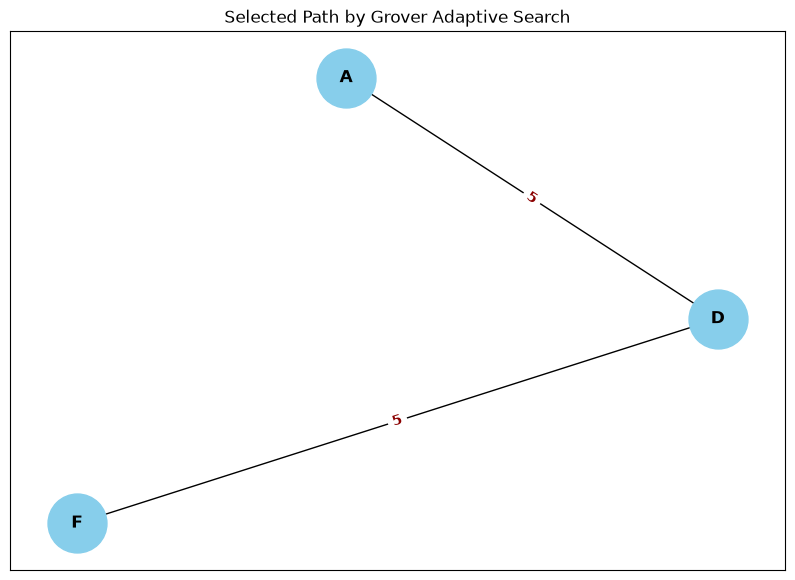

In [18]:
R = nx.Graph()
R.add_edges_from((u, v, G[u][v]) for u, v in selected_edges)
draw_network_graph(R, "Selected Path by Grover Adaptive Search")

### **<u>Shortest route classically</u>** 


> Classical Dijkstra Result
Route: ['A', 'D', 'F']
Cost: 10


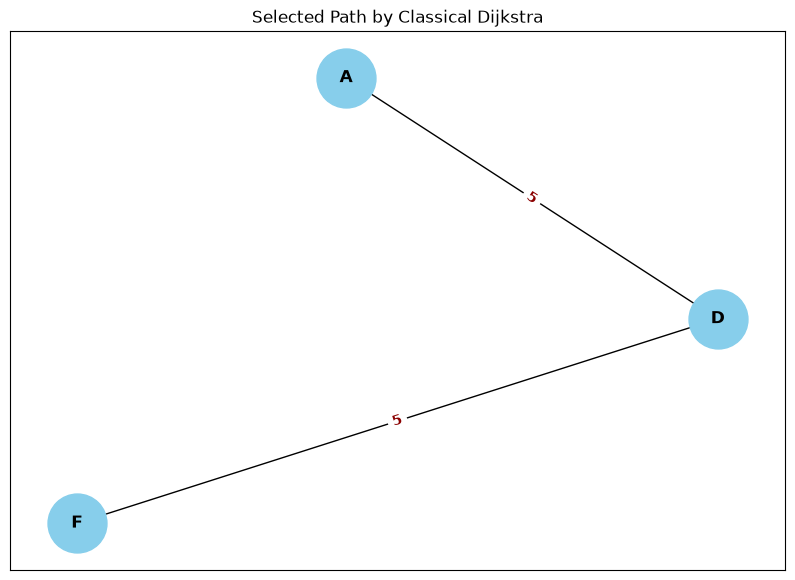

In [19]:
classical_route = nx.shortest_path(G, source=SOURCE, target=DESTINATION, weight="weight")   # default is dijkistra
classical_cost = nx.shortest_path_length(G, source=SOURCE, target=DESTINATION, weight="weight")

print("\n> Classical Dijkstra Result")
print("Route:", classical_route)
print("Cost:", classical_cost)

D = nx.Graph()
classical_edges = list(zip(classical_route[:-1], classical_route[1:]))
D.add_edges_from((u, v, G[u][v]) for u, v in classical_edges)
draw_network_graph(D, "Selected Path by Classical Dijkstra")
